# Supplemental Figure 1, Panels I-J

# Setup

In [1]:
# load packages
library(tidyverse)
library(rtracklayer)
library(GenomicRanges)
library(patchwork)
library(here)
here::i_am("figures/SuppFig1/PanelI_J/PanelI_J.ipynb")

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           patchwork_1.3.0      rtracklayer_1.58.0  
 [4] GenomicRanges_1.50.2 GenomeInfoDb_1.34.9  IRanges_2.32.0      
 [7] S4Vectors_0.36.2     BiocGenerics_0.44.0  lubridate_1.9.4     
[10] forcats_1.0.0        stringr_1.5.1        dplyr_1.1.4         
[13] pur

# Categorize ATAC-seq peaks using ccRE annotations

In [2]:
#cCRE annotation of ATAC-seq peaks

#read in BED files:
# ATAC peaks
atac <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
)

atac_gr <- GRanges(
  seqnames = atac$seqnames,
  ranges  = IRanges(start = atac$start, end = atac$end),
  logFC   = atac$logFC
)

# cCRE annotations
# downloaded from https://downloads.wenglab.org/Registry-V3/Seven-Group/ENCFF428XFI_ENCFF280PUF_ENCFF469WVA_ENCFF644EEX.7group.bed
cCRE <- read.delim(
  here(
    "figures", "SuppFig1", "PanelI_J",
    "ENCFF428XFI_ENCFF280PUF_ENCFF469WVA_ENCFF644EEX.7group.bed"
  ),
  sep    = "\t",
  header = FALSE
)

ccRE_gr <- GRanges(
  seqnames = cCRE$V1,
  ranges  = IRanges(start = cCRE$V2, end = cCRE$V3),
  state   = cCRE$V10
)

# row metadata
atac_meta <- read.delim(
  here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
  sep = "\t"
)

# find overlaps between ATAC and chromHMM regions
hits <- findOverlaps(atac_gr, ccRE_gr)

# 3. Make a data frame of results
overlap_df <- data.frame(
    peak_id = queryHits(hits), #row # in ATAC peaks data frame
    cCRE_id = subjectHits(hits), #row # in chromHMM data frame
    peak_chr = seqnames(atac_gr)[queryHits(hits)], #ATAC-seq peak coordinates
    peak_start = start(atac_gr)[queryHits(hits)],
    peak_end = end(atac_gr)[queryHits(hits)],
    logFC = mcols(atac_gr)$logFC[queryHits(hits)],
    cCRE_chr = seqnames(ccRE_gr)[subjectHits(hits)], #chromHMM state coordinates
    cCRE_start = start(ccRE_gr)[subjectHits(hits)],
    cCRE_end = end(ccRE_gr)[subjectHits(hits)],
    cCRE_state  = mcols(ccRE_gr)$state[subjectHits(hits)]  #chromHMM state
)

#multiple annotations can overlap one ATAC-seq peak. Here, applying the rule to keep only the annotation with the largest overlap
overlap_df <- overlap_df %>%
  mutate(overlap_bp = pmin(peak_end, cCRE_end) - pmax(peak_start, cCRE_start) + 1) %>% #compute overlaps
  group_by(peak_id) %>%
  slice_max(overlap_bp, n = 1) %>%
  ungroup()

#add annotations back to ATAC-seq peaks
atac$cCRE_state <- NA
atac$cCRE_state[overlap_df$peak_id] <- overlap_df$cCRE_state

#write out annotations
atac %>% select(seqnames,start,end, ID, cCRE_state) %>% write.table("consensus_filt_annot_cCRE.tsv", sep='\t',row.names=FALSE)

# Generate plot (figure I)

In [5]:
#compare accessibility changes due to BAFinh between PLS = "Promoter-Like Signature", dELS = "distal Enhancer-Like Signature", and "CTCF-only" annotations

cCRE_plot <- atac %>% mutate(
    cCRE_state_slim=case_when(grepl("dELS", cCRE_state) ~ "dELS", 
                              grepl("PLS", cCRE_state) ~ "PLS", 
                              grepl("CTCF-only", cCRE_state) ~ "CTCF", 
                              TRUE ~ "other")) %>%
    filter(cCRE_state_slim!="other") %>% #exclude non-PLS/dELS/CTCF-bound regions
    ggplot(aes(y=factor(cCRE_state_slim, levels=c("CTCF", "PLS", "dELS")), x=logFC)) + 
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_vline(xintercept=0, linetype=2) + 
    geom_violin(aes(fill=cCRE_state_slim)) + 
    geom_boxplot(width=.1, outlier.shape=NA) +
    xlab("Log2 fold change, accessibility") + ylab("cCRE Type") +
    scale_fill_manual(values=c("PLS"="#268c43", "dELS"="#daa520", "CTCF"="#888888")) + ggtitle("cCRE")

#enumerate cREs in each annotation category
atac %>% mutate(
    cCRE_state_slim=case_when(grepl("dELS", cCRE_state) ~ "dELS", 
                              grepl("PLS", cCRE_state) ~ "PLS", 
                              grepl("CTCF-only", cCRE_state) ~ "CTCF", 
                              TRUE ~ "other")) %>%
    filter(cCRE_state_slim!="other") %>% group_by(cCRE_state_slim) %>% summarize(n())

cCRE_state_slim,n()
<chr>,<int>
CTCF,10434
PLS,9543
dELS,14846


# Generate plot (figure J)

In [7]:
#using ChIP-based annotations (see diagram included with Supp Fig 1J)
chip_annot_plot <- atac %>% mutate(type = case_when(grepl("enh", type) ~ "Enhancer", grepl("prom", type) ~ "Promoter", grepl("CTCF_only", type) ~ "CTCF", TRUE ~ "Other")) %>%
    filter(type!="Other") %>% 
    ggplot(aes(y=factor(type, levels=c("CTCF", "Promoter", "Enhancer")), x=logFC)) + 
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_vline(xintercept=0, linetype=2) + 
    geom_violin(aes(fill=type)) + 
    geom_boxplot(width=.1, outlier.shape=NA) +
    xlab("Log2 fold change, accessibility") + ylab("cRE Type (ChIP-based annotations)") +
    scale_fill_manual(values=c("Promoter"="#268c43", "Enhancer"="#daa520", "CTCF"="#888888")) + ggtitle("ChIP-based")

atac %>% mutate(type = case_when(grepl("enh", type) ~ "Enhancer", grepl("prom", type) ~ "Promoter", grepl("CTCF_only", type) ~ "CTCF", TRUE ~ "Other")) %>%
    filter(type!="Other") %>% group_by(type) %>% summarize(n())

type,n()
<chr>,<int>
CTCF,18611
Enhancer,35045
Promoter,15658


# Assemble figure panels

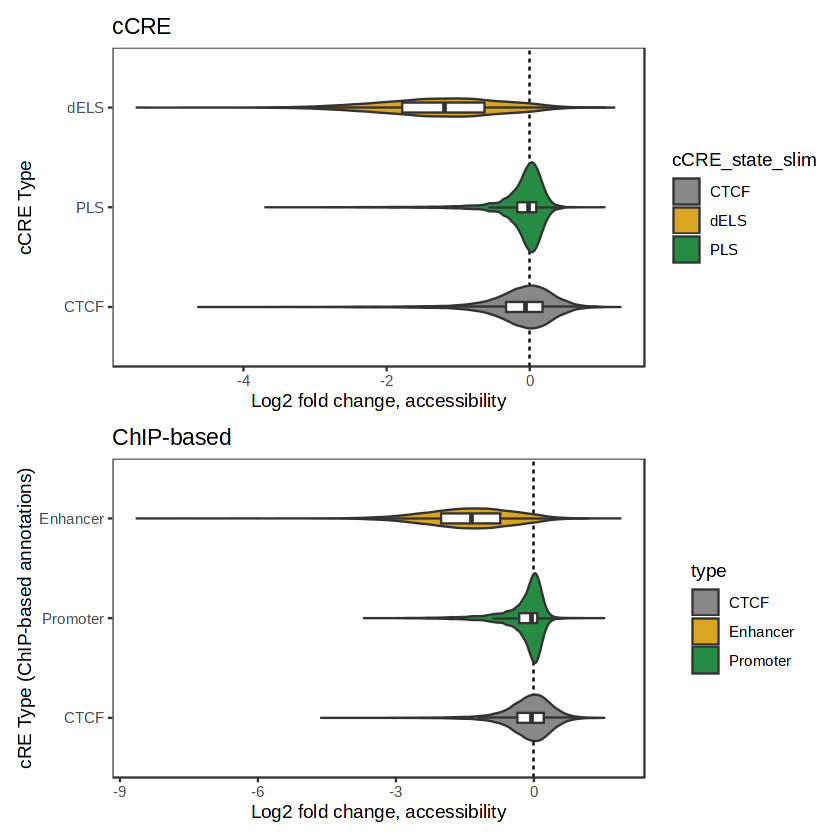

In [8]:
cCRE_plot / chip_annot_plot
ggsave("PanelI_J.pdf", width=5, height=5)

# Statistics

In [9]:
#compare accessibility fold changes between enhancer classes (Enhancer, dELS) and non-enhancer classes (Promoter/PLS, CTCF)

#ChIP-based annotations
chip_stats <- atac %>% mutate(type = case_when(grepl("enh", type) ~ "Enhancer", grepl("prom", type) ~ "Promoter", grepl("CTCF_only", type) ~ "CTCF", TRUE ~ "Other")) %>%
    filter(type!="Other") 
wilcox.test(chip_stats[chip_stats$type=="Enhancer",]$logFC, chip_stats[chip_stats$type=="Promoter",]$logFC, alternative="less")$p.value
wilcox.test(chip_stats[chip_stats$type=="Enhancer",]$logFC, chip_stats[chip_stats$type=="CTCF",]$logFC, alternative="less")$p.value

#ENCODE cCRE annotations
cCRE_stats <- atac %>% mutate(
    cCRE_state_slim=case_when(grepl("dELS", cCRE_state) ~ "dELS", 
                              grepl("PLS", cCRE_state) ~ "PLS", 
                              grepl("CTCF-only", cCRE_state) ~ "CTCF", 
                              TRUE ~ "other")) %>%
    filter(cCRE_state_slim!="other") 
wilcox.test(cCRE_stats[cCRE_stats$cCRE_state_slim=="dELS",]$logFC, cCRE_stats[cCRE_stats$cCRE_state_slim=="PLS",]$logFC, alternative="less")$p.value
wilcox.test(cCRE_stats[cCRE_stats$cCRE_state_slim=="dELS",]$logFC, cCRE_stats[cCRE_stats$cCRE_state_slim=="CTCF",]$logFC, alternative="less")$p.value

[1] 0

[1] 0

[1] 0

[1] 0